# Web APIs 第一天：DOM 获取与属性操作

## 课程说明

本篇是 JavaScript 总课程第 06 天，对应 **Web APIs 第一天**。目标是掌握 DOM 获取与属性操作，设置元素内容和属性，控制元素样式，再用间歇定时器完成注册协议倒计时和自动轮播图。

本篇依据[百度网盘课程资料](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)中「2.web APIs / 资料 / web APIs第一天」的 72 页讲义与课程阶段说明整理，提取码为 `9987`。

**资料状态：**讲义已完整读取。原 Markdown、18 份课堂 HTML、素材和配套作业尚未下载成功；本篇先保存讲义内容，后续补齐原码及作业。标为“讲义原示例”的代码根据讲义中的代码图核对整理；其他示例明确标为“整理示例”，不能视为配套课堂源码。

所有代码作为 Markdown 展示，在浏览器练习时写入对应 HTML 的 `<script>`，不同示例分别执行，避免变量重复声明。教学图已直接嵌入；示例中图片路径仍需真实课程素材。

## 0. 变量声明：const 与 let

### 0.1 优先使用 const

本日进入 DOM 前先复习变量声明。课程建议先用 `const`，发现后面需要重新赋值，再改为 `let`；后续不优先使用旧式的 `var`。

字符串拼接或输入数字后做计算，只要变量没有重新赋值，就可以用 `const`。按讲义第 5 页改写的整理示例：

```javascript
const uname = '刘德华'
const song = '忘情水'
document.write(uname + song)

const num1 = +prompt('请输入第一个数值：')
const num2 = +prompt('请输入第二个数值：')
alert(`两者相加的结果是：${num1 + num2}`)
```

讲义第 6 页的下面两个例子不能直接把 `let` 改为 `const`，因为 `num = num + 1` 和 `i++` 都会重新赋值。讲义原示例：

```javascript
let num = 1
num = num + 1
console.log(num)  // 结果是 2

for (let i = 0; i < nums.length; i++) {
  document.write(nums[i])
}
```

循环片段依赖前面已有的 `nums` 数组，不是独立的完整程序。

### 0.2 const 可以修改数组和对象的成员

`const` 声明变量时必须立即初始化，后续不能重新赋值。对于数组和对象，变量保存的是引用地址。调用 `push()`、增加属性、修改属性，都还是操作同一个对象，没有更换引用。

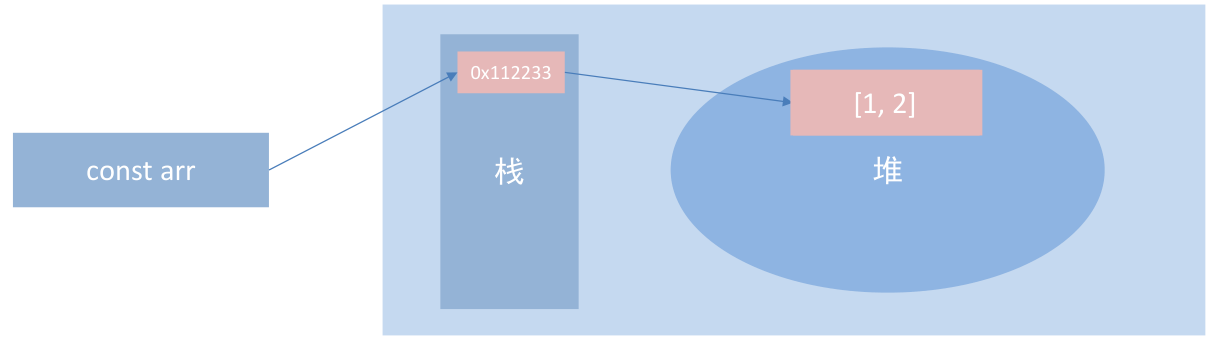

图中用栈和堆解释引用：对象内容可以变化，变量保存的引用保持不变。对应讲义第 7、9 页的整理示例：

```javascript
const arr = ['red', 'green']
arr.push('pink')
console.log(arr)  // ['red', 'green', 'pink']

const person = {
  uname: 'pink老师',
  age: 18,
  gender: '女'
}
person.address = '武汉黑马'
person.gender = '男'
console.log(person.gender)  // 男
```

### 0.3 重新绑定数组或对象会报错

讲义第 10 页的错误例子，分别运行：

```javascript
const names = []
names = [1, 2, 3]
```

```javascript
const obj = {}
obj = {
  uname: 'pink老师'
}
```

两段都把新创建的数组或对象重新赋给 `const` 变量，会抛出 `TypeError`。讲义右侧的正确写法保留原对象，只修改内部成员：

```javascript
const names = []
names[0] = 1
names[1] = 2
names[2] = 3

const obj = {}
obj.uname = 'pink老师'
```

选择依据是有没有重新赋值；绑定不变用 `const`，基本值需要变化或引用需要指向另一个对象时用 `let`。

## 1. Web API 基本认知

### 1.1 作用和分类

前五天学习 JavaScript 语言基础。Web APIs 提供浏览器环境的接口，让 JavaScript 操作 HTML 页面和浏览器。

| 部分 | 名称 | 用途 |
| --- | --- | --- |
| ECMAScript | JavaScript 语言基础 | 变量、语法和数据类型等语言规则 |
| DOM | Document Object Model，文档对象模型 | 访问和操作页面文档 |
| BOM | Browser Object Model，浏览器对象模型 | 操作浏览器窗口等环境 |

### 1.2 什么是 DOM

DOM 是呈现和操作 HTML 或 XML 文档的 API。对本课程来说，就是浏览器提供的一套操作网页内容的功能，用来开发页面特效和用户交互。

### 1.3 DOM 树

浏览器把 HTML 文档表示成树状结构，称为文档树或 DOM 树。它直观体现标签之间的关系：`html` 包含 `head` 和 `body`，它们又包含其他元素和文字。

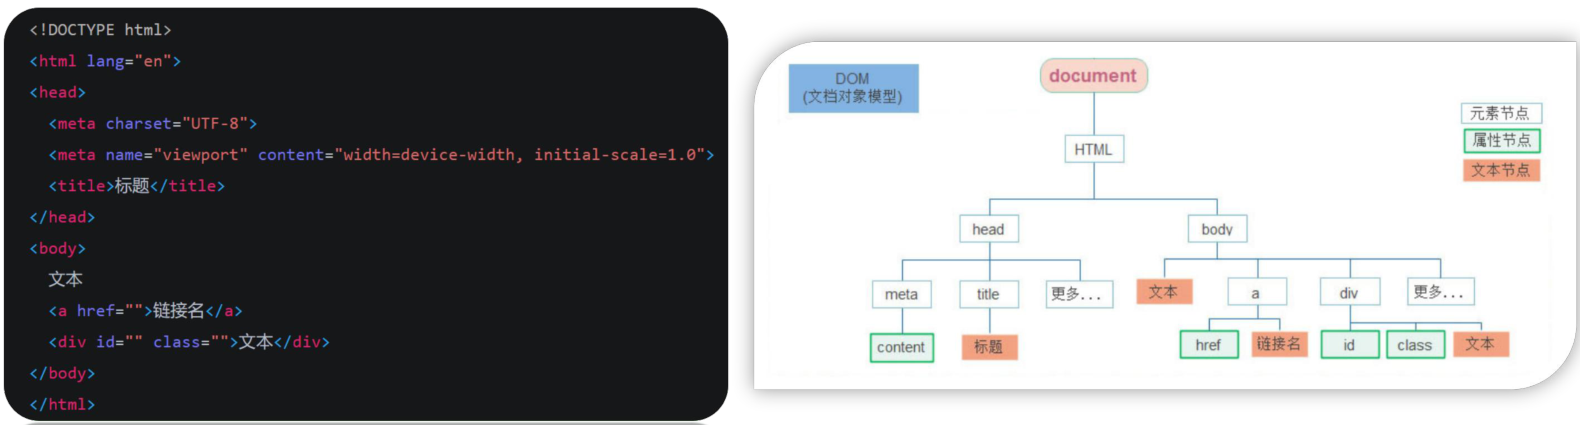

左边是 HTML，右边是对应结构；图中还标出了属性和文本节点。获取元素时，就是从文档结构中定位目标。

### 1.4 DOM 对象和 document

DOM 对象由浏览器根据 HTML 标签生成。常用标签属性可以通过对象访问，修改对象属性时页面标签随之变化。核心思想是把网页内容当成对象处理。

`document` 是 DOM 提供的对象，用于访问和操作当前页面文档，前面学过的 `document.write()` 就是它的方法。整理示例：

```javascript
const box = document.querySelector('.box')
console.log(box)
console.dir(box)
```

前提是页面有 `.box` 元素；控制台可以看到对应标签和对象属性。下面学习具体获取方法。

## 2. 获取 DOM 元素

### 2.1 querySelector：获取第一个匹配元素

操作标签前先获取其 DOM 对象。参数是有效的 CSS 选择器字符串，返回第一个匹配元素，找不到时返回 `null`。整理示例：

```javascript
const box = document.querySelector('.box')
const nav = document.querySelector('#nav')
const firstLi = document.querySelector('ul li')
const thirdLi = document.querySelector('ul li:nth-child(3)')
```

类名有 `.`，ID 有 `#`，选择器外面有引号。即使匹配多个元素，`querySelector()` 也只取第一个。结果是 `null` 时不能直接访问属性，应检查 HTML 和选择器；练习脚本放在目标标签后面，确保元素已经存在。

### 2.2 querySelectorAll：获取匹配集合

返回 `NodeList` 伪数组，有 `length` 和索引，但没有 `push()`、`pop()` 等数组方法。必须遍历后取得单个元素，再修改属性；只有一个匹配时仍是集合，没有匹配时长度为 `0`。

讲义第 30 页要求依次输出三个 `li` 的 DOM 对象，整理示例：

```html
<ul>
  <li>刘德华</li>
  <li>张学友</li>
  <li>郭富城</li>
</ul>
<script>
  const lis = document.querySelectorAll('ul li')
  for (let i = 0; i < lis.length; i++) {
    console.log(lis[i])
  }
</script>
```

控制台依次出现三个元素。不能直接用 `lis.style` 批量设置样式，因为它是集合。

| 方法 | 返回值 | 修改方法 |
| --- | --- | --- |
| querySelector | 第一个元素或 null | 对单个元素直接读写 |
| querySelectorAll | NodeList 集合 | 用索引或遍历取出元素 |

讲义第 28 页文字中的 `querySelectAll()` 是拼写错误，正确为 `querySelectorAll()`。

### 2.3 其他获取方法（了解）

讲义第 31 页原示例：

```javascript
// 根据id获取一个元素
document.getElementById('nav')
// 根据 标签获取一类元素 获取页面 所有div
document.getElementsByTagName('div')
// 根据 类名获取元素 获取页面 所有类名为 w 的
document.getElementsByClassName('w')
```

这些方法直接写 ID 名、标签名或类名，不写 `#nav`、`.w`。本课程重点仍是两种 CSS 选择器方法。

## 3. 操作元素内容

### 3.1 innerText：纯文本

获取元素后用点语法读写内容。`innerText` 写入纯文本，不解析 HTML 标签。讲义第 35 页原示例：

```javascript
const info = document.querySelector('.info')
// 获取标签内部的文字
// console.log(info.innerText)
// 添加/修改标签内部文字内容
info.innerText = '嗨嗨,俺是刘德华~ '
```

原内容被替换；如果写 `<strong>刘德华</strong>`，标签会作为文字显示。

### 3.2 innerHTML：可以解析 HTML

`innerHTML` 会解析写入的标签，多标签内容建议使用模板字符串。讲义第 36 页原示例：

```javascript
const info = document.querySelector('.info')
// 获取标签内部的文字
// console.log(info.innerHTML)
// 添加/修改标签内部文字内容
info.innerHTML = `嗨嗨,俺是<strong>刘德华</strong>~ `
```

`strong` 被解析，“刘德华”显示为加粗。讲义第 37 页的“三者”实际指本节两种属性；普通文本用 `innerText`，需要生成 HTML 用 `innerHTML`。

## 3.3 案例：年会抽奖

需求是从名单数组随机抽取一等奖、二等奖和三等奖，显示到对应标签。它结合上一天的随机数和本日的元素内容操作。

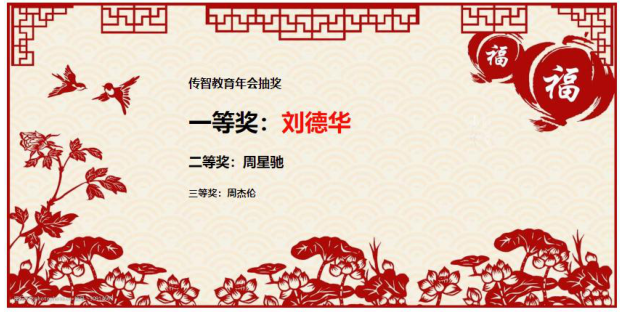

讲义步骤：声明名单数组；随机生成下标并取姓名；获取奖项对应 `span`，用 `innerText` 或 `innerHTML` 写入；二等奖、三等奖依次类推。

讲义第 39 页的“0～数组长度”作为下标应为 **0 到长度减 1**。下面是整理示例；通过删除已抽中的成员确保奖项不重复，配套课堂原码待下载核对。

```html
<p>一等奖：<span class="one"></span></p>
<p>二等奖：<span class="two"></span></p>
<p>三等奖：<span class="three"></span></p>
<script>
  const personArr = ['周杰伦', '刘德华', '周星驰', 'Pink老师', '张学友']
  const prizes = document.querySelectorAll('span')
  for (let i = 0; i < prizes.length; i++) {
    const random = Math.floor(Math.random() * personArr.length)
    prizes[i].innerText = personArr[random]
    personArr.splice(random, 1)
  }
</script>
```

每次根据当前数组长度计算下标，不能一直用最初人数；名单人数应不少于奖项数量。

## 4. 操作元素属性

### 4.1 常用属性：src、title、href

语法是 `对象.属性 = 值`，例如修改 `src` 更换图片，设置 `title` 更改悬停提示。讲义第 42 页原示例：

```javascript
// 1. 获取元素
const pic = document.querySelector('img')
// 2. 操作元素
pic.src = './images/b02.jpg'
pic.title = '刘德华黑马演唱会'
```

HTML 中需要有 `img`，对应目录需要有这张图片；运行后图片切换，悬停可看到提示。

### 4.2 练习：刷新随机显示图片

讲义要求先获取图片，再随机得到序号，最后设置对应 `src`。整理示例假设素材是 `b01.jpg` 至 `b06.jpg`：

```html
<img src="./images/b01.jpg" alt="随机图片">
<script>
  const pic = document.querySelector('img')
  const random = Math.floor(Math.random() * 6) + 1
  pic.src = `./images/b0${random}.jpg`
</script>
```

序号范围是 `1～6`，匹配文件编号，实际数量和文件名以素材为准。随机逻辑只在加载或刷新时执行。

### 4.3 通过 style 操作 CSS

讲义第 47 页原示例：

```javascript
const box = document.querySelector('.box')
// 修改元素样式
box.style.width = '200px'
box.style.marginTop = '15px'
box.style.backgroundColor = 'pink'
```

修改样式从 `style` 引出；连字符属性改用小驼峰，如 `padding-left` → `paddingLeft`；宽度、边距等按需要加 `px` 等单位，颜色则直接写颜色值。

### 4.4 练习：随机更换页面背景

`body` 是唯一标签，可直接通过 `document.body.style` 修改背景。整理示例假设图片是 `b01.jpg` 至 `b06.jpg`：

```javascript
const random = Math.floor(Math.random() * 6) + 1
document.body.style.backgroundImage = `url(./images/b0${random}.jpg)`
```

CSS 背景需要 `url(...)`，和 `img.src` 直接接收路径不同。

### 4.5 className：整体替换类名

修改多个样式时，先写 CSS 类再修改类名，比逐个设置 `style` 方便。整理示例：

```html
<style>
  .box { width: 100px; height: 100px; }
  .active { background-color: pink; color: red; }
</style>
<div class="box">盒子</div>
<script>
  const box = document.querySelector('.box')
  box.className = 'box active'
</script>
```

DOM 属性写 `className`。直接赋值会替换整个 `class` 值，若只写 `'active'` 就丢失原 `box` 类；上例同时保留 `box`，所以宽高样式仍存在。

### 4.6 classList：增删和切换类

整理示例：

```javascript
const box = document.querySelector('.box')
// 追加一个类
box.classList.add('active')
// 删除一个类
box.classList.remove('active')
// 切换一个类
box.classList.toggle('active')
```

参数不带 `.`。`toggle` 有则删除、没有则添加；三行依次运行后最终存在 `active`。`classList` 不影响其他类名，`className` 用于整体设置类名组合。

## 4.7 练习：随机轮播图

刷新后随机显示一张图片，同时改变标题、底部背景颜色和小圆点高亮。对象数组每项存 `url`、`title`、`color`，同一个下标控制四个部分。

下面根据讲义第 55 页的八条数据制作整理示例。小圆点数量与数据条数一致。

```html
<style>
  .slider { width: 560px; }
  .slider-wrapper img { width: 100%; display: block; }
  .slider-footer { padding: 12px; color: white; }
  .slider-footer p { margin: 0 0 10px; }
  .slider-indicator { display: flex; gap: 8px; padding: 0; margin: 0; list-style: none; }
  .slider-indicator li { width: 10px; height: 10px; border-radius: 50%; background: #888; }
  .slider-indicator li.active { background: white; }
</style>
<div class="slider">
  <div class="slider-wrapper">
    <img src="./images/slider01.jpg" alt="轮播图片">
  </div>
  <div class="slider-footer">
    <p>对人类来说不会太超前了？</p>
    <ul class="slider-indicator">
      <li class="active"></li>
      <li></li>
      <li></li>
      <li></li>
      <li></li>
      <li></li>
      <li></li>
      <li></li>
    </ul>
  </div>
</div>
<script>
  const sliderData = [
    { url: './images/slider01.jpg', title: '对人类来说不会太超前了？', color: 'rgb(100, 67, 68)' },
    { url: './images/slider02.jpg', title: '开启剑与雪的黑暗传说！', color: 'rgb(43, 35, 26)' },
    { url: './images/slider03.jpg', title: '真正的jo厨出现了！', color: 'rgb(36, 31, 33)' },
    { url: './images/slider04.jpg', title: '李玉刚：让世界通过B站看到东方大国文化', color: 'rgb(139, 98, 66)' },
    { url: './images/slider05.jpg', title: '快来分享你的寒假日常吧~', color: 'rgb(67, 90, 92)' },
    { url: './images/slider06.jpg', title: '哔哩哔哩小年YEAH', color: 'rgb(166, 131, 143)' },
    { url: './images/slider07.jpg', title: '一站式解决你的电脑配置问题！！！', color: 'rgb(53, 29, 25)' },
    { url: './images/slider08.jpg', title: '谁不想和小猫咪贴贴呢！', color: 'rgb(99, 72, 114)' }
  ]
  const img = document.querySelector('.slider-wrapper img')
  const footer = document.querySelector('.slider-footer')
  const title = document.querySelector('.slider-footer p')
  const random = Math.floor(Math.random() * sliderData.length)
  const data = sliderData[random]
  img.src = data.url
  title.innerHTML = data.title
  footer.style.backgroundColor = data.color
  document.querySelector('.slider-indicator .active').classList.remove('active')
  document.querySelector(`.slider-indicator li:nth-child(${random + 1})`).classList.add('active')
</script>
```

数组下标从 `0` 开始，`nth-child` 从 `1` 开始，所以使用 `random + 1`。先移除初始高亮，避免多个点同时亮。讲义文字“addClass”在本课实际应写原生方法 `classList.add()`。

## 4.8 表单元素属性

输入框的内容用 `value`，类型用 `type`。显示密码的本质是将类型从 `password` 改成 `text`；点击事件在后面的课程学习。整理示例：

```html
<input type="text">
<script>
  const input = document.querySelector('input')
  input.value = '用户名'
  input.type = 'password'
</script>
```

`input` 的输入内容不用 `innerHTML` 设置。表单的布尔状态通过 `true`、`false` 控制：

| 属性 | true | false |
| --- | --- | --- |
| disabled | 禁用按钮或输入框 | 允许使用 |
| checked | 勾选复选框或单选框 | 取消勾选 |
| selected | 选中 option | 取消对应 option 的选中 |

整理示例：

```html
<input class="choice" type="checkbox">
<button class="submit">提交</button>
<script>
  const choice = document.querySelector('.choice')
  const button = document.querySelector('.submit')
  choice.checked = true
  button.disabled = true
</script>
```

复选框被选中，按钮无法点击。恢复按钮使用 `button.disabled = false`，这里是布尔值，不是字符串 `'false'`。HTML 中 `disabled="false"` 仍表示存在禁用属性，不能用它取消禁用。

## 4.9 自定义属性：data-* 与 dataset

标准属性如 `id`、`title` 由标签提供；保存自己的编号等信息时，可用 HTML5 的自定义属性，标签上以 `data-` 开头，DOM 对象上通过 `dataset` 获取。

讲义第 60 页原示例：

```html
<body>
  <div class="box" data-id="10">盒子</div>
  <script>
    const box = document.querySelector('.box')
    console.log(box.dataset.id)
  </script>
</body>
```

输出字符串 `"10"`，不是数字，参与数值运算前需转换。

## 5. 定时器：间歇函数

### 5.1 作用与开启

网页倒计时和自动轮播需要隔一段时间自动执行代码。课程当天介绍 `setInterval(函数, 间隔时间)`，单位是毫秒，返回定时器 id。

讲义第 65 页原示例：

```javascript
function repeat() {
  console.log('前端程序员，就是头发多咋滴~~')
}
// 每隔一秒调用repeat函数
setInterval(repeat, 1000)
```

第一个参数传 `repeat`，不能写 `repeat()`；后者会立即调用函数，把返回值交给定时器。首次回调在等待间隔后执行，页面需要初始内容时应先设置。

### 5.2 关闭定时器

保存返回的 id，满足停止条件时传给 `clearInterval`。讲义第 66 页原示例：

```javascript
let timer = setInterval(function() {
  console.log('hi~~')
}, 1000)
clearInterval(timer)
```

这个例子创建后立即清除，因而没有第一次输出；实际案例一般在达到条件后清除，例如倒计时到零。

## 5.3 案例：阅读注册协议倒计时

讲义需求是按钮 60 秒后才可用。先禁用按钮，再获取元素，每秒减一并更新文字；到零时清除定时器、改为“同意”，最后恢复按钮。

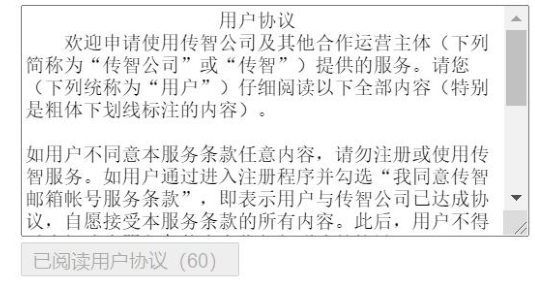

按讲义步骤制作的整理示例，协议区域只保留占位文本：

```html
<textarea rows="8" cols="50" readonly>用户协议……</textarea>
<br>
<button class="agree" disabled>已阅读用户协议（60）</button>
<script>
  const button = document.querySelector('.agree')
  let seconds = 60
  const timer = setInterval(function () {
    seconds--
    button.innerText = `已阅读用户协议（${seconds}）`
    if (seconds === 0) {
      clearInterval(timer)
      button.innerText = '同意'
      button.disabled = false
    }
  }, 1000)
</script>
```

`seconds` 需要变化，用 `let`；元素和 id 的绑定不变，可用 `const`。结束时既要恢复按钮也要停止定时器，避免显示负数。初始是 `60`，第一次回调显示 `59`，最后改成“同意”。练习可临时改为 5 秒，同时修改初始文字。

## 6. 综合案例：轮播图定时器版

需求是每隔一秒切换图片、标题、底部颜色和小圆点。把随机轮播的随机下标改为顺序递增下标。

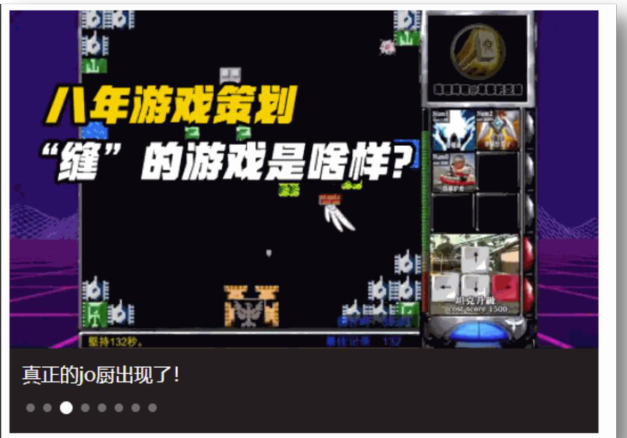

步骤是准备数据、获取元素、设置定时器、递增索引、同步更新展示、处理循环边界。**递增后立即检查是否达到数组长度，先归零再取数据。**

继续使用“4.7 随机轮播图”中的 HTML、CSS 和 `sliderData` 数组，把原脚本中从 `const img = ...` 开始到脚本结尾的代码全部替换成下面的整理示例，避免重复声明 `img`、`footer`、`title`。

```javascript
const img = document.querySelector('.slider-wrapper img')
const footer = document.querySelector('.slider-footer')
const title = document.querySelector('.slider-footer p')
const indicators = document.querySelectorAll('.slider-indicator li')
let i = 0

// 初始页面与第 0 条数据对应
img.src = sliderData[i].url
title.innerHTML = sliderData[i].title
footer.style.backgroundColor = sliderData[i].color

setInterval(function () {
  i++
  if (i >= sliderData.length) {
    i = 0
  }
  const data = sliderData[i]
  img.src = data.url
  title.innerHTML = data.title
  footer.style.backgroundColor = data.color
  document.querySelector('.slider-indicator .active').classList.remove('active')
  indicators[i].classList.add('active')
}, 1000)
```

上例小圆点数量与数据条数相等，第一项初始已有 `active`。索引顺序为 `0 → 1 → … → 7 → 0`；如果访问数组后才检查边界，会读到 `undefined`，继续读取 `url` 就会报错。

## 7. 当天练习与作业要求

讲义第 71 页要求整理当天笔记、练习用户协议倒计时、至少写三遍自动轮播图，并完成测试题、作业及预习。

| 练习 | 应观察到的结果 |
| --- | --- |
| 输出 3 个 li 的 DOM 对象 | 控制台依次出现三个元素 |
| 年会抽奖 | 三个奖项姓名写入对应标签 |
| 刷新随机更换图片与背景 | 路径正确，刷新后可能变化 |
| 随机轮播图 | 图片、文字、颜色和小圆点对应同一项 |
| 用户协议倒计时 | 先禁用，到零后显示“同意”并可用 |
| 自动轮播 | 定时切换，最后一张后回到第一张 |

**配套作业待补：**未取得「07-作业」的题目和答案文件，也未取得「04-code」的 18 份原 HTML。上表仅为已读讲义要求，不替代配套题目。

## 8. 本日关键检查

| 易错位置 | 检查内容 |
| --- | --- |
| const 与 let | 改成员和重新绑定变量有区别 |
| 获取元素 | 字符串选择器；集合要遍历；查不到单个元素为 null |
| 内容修改 | innerText 不解析 HTML，innerHTML 解析 |
| 图片与背景 | img 用 src，背景用 backgroundImage 和 url |
| 样式修改 | 小驼峰命名，需要时加单位 |
| 类名 | className 整体替换，classList 增删指定类 |
| 表单 | 输入值用 value，布尔状态用 true 或 false |
| 自定义属性 | 标签写 data-*，对象用 dataset |
| 定时器 | 传函数本身，保存 id，条件满足后清除 |
| 轮播边界 | 索引递增后先归零，再访问数组 |